# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [2]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Бісюк Роман'      # прізвище та ім'я
GROUP        = 'ШІ-34'      # шифр групи, наприклад СШІ-31
NUMBER       = 1       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Бісюк Роман | ШІ-34 | номер 1


In [3]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 1   ·   Бісюк Роман   ·   ШІ-34

   Ринок:  Odesa
   Товар:  хліб пшеничний   (у наборі даних: Bread (wheat) - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** |28.10.2026 |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('ціни_україна_2014_2017.csv')
df['date'] = pd.to_datetime(dict(year=df['рік'], month=df['місяць'], day=1))

s = df[(df['ринок'] == MARKET) & (df['товар'] == GOOD)].set_index('date')['ціна'].sort_index()

grid = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
s = s.reindex(grid)

print('Місяців у сітці:', len(s))
print('З виміром:', s.notna().sum())
print('Пропуск:', s[s.isna()].index.strftime('%m.%Y').tolist())
print('Записів у всьому наборі за 08.2017:', (df['date'] == '2017-08-01').sum())

Місяців у сітці: 46
З виміром: 45
Пропуск: ['08.2017']
Записів у всьому наборі за 08.2017: 0


**Висновок до завдання 1:**

Сітка містить 46 місяців, вимір є для 45. Пропуск один, у серпні 2017 року. Він виник не через Одесу чи хліб: за цей місяць у наборі немає жодного запису по всіх ринках і товарах, тобто дані просто не зібрали. У сирому ряді пропуск не видно, він з'являється лише після накладання ряду на повну місячну сітку.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [5]:
f_ffill  = s.ffill()
f_linear = s.interpolate()
f_season = s.fillna(s.shift(12))   # те саме значення рік тому

print('Перенесення останнього:', f_ffill['2017-08-01'])
print('Лінійна інтерполяція:  ', f_linear['2017-08-01'])
print('Значення рік тому:     ', f_season['2017-08-01'])

s = f_linear   # обраний спосіб

print()
print('Місяців із даними по ринках (Крим, Севастополь):')
print(df[df['ринок'].isin(['Crimea', 'm. Sevastopol'])].groupby('ринок')['date'].agg(['min', 'max', 'nunique']))

Перенесення останнього: 9.46
Лінійна інтерполяція:   9.46
Значення рік тому:      9.5

Місяців із даними по ринках (Крим, Севастополь):
                     min        max  nunique
ринок                                       
Crimea        2014-03-01 2014-03-01        1
m. Sevastopol 2014-03-01 2014-04-01        2


**Висновок до завдання 2:**
Перенесення і лінійна інтерполяція дають 9,46 грн, значення рік тому дає 9,50 грн.
Обираю лінійну інтерполяцію: у липні й вересні ціна однакова (9,46), тож у серпні вона, найімовірніше, не змінювалась. До того ж така сама інтерполяція є в Orange.
Заповнювати не можна, коли ринок зник повністю: для Криму є лише 03.2014, і заповнення вигадало б 45 місяців цін.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

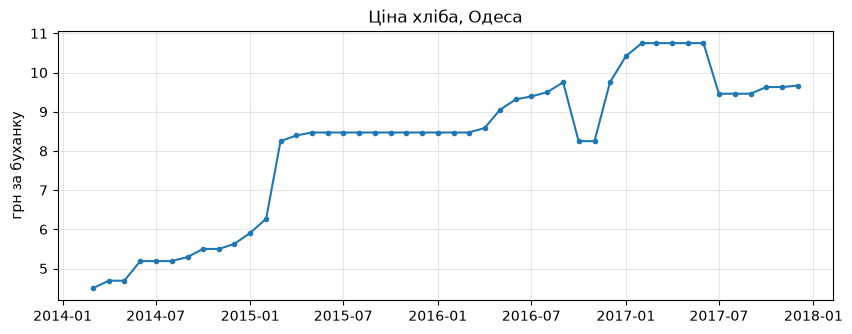

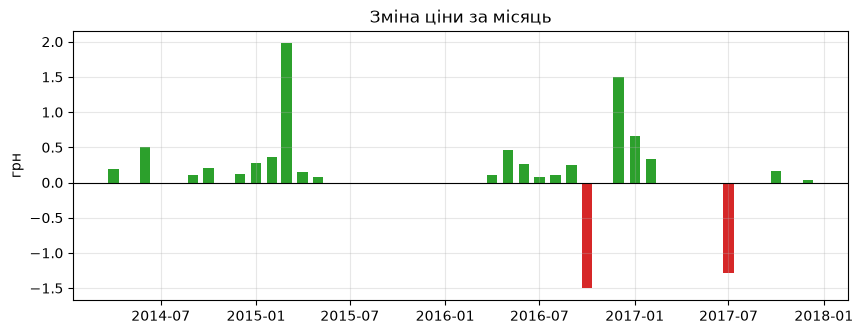

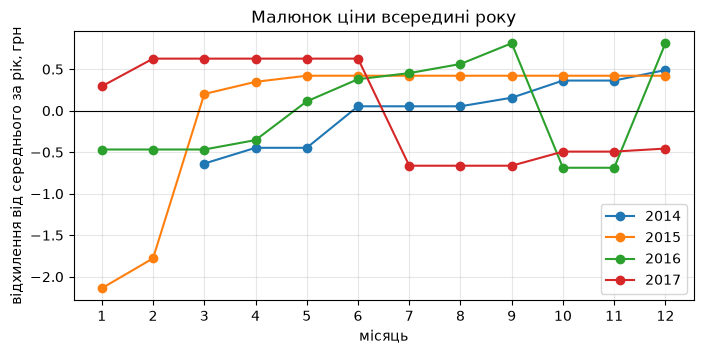

In [6]:
# Графік 1. Як змінювалась ціна з часом?
plt.figure(figsize=(10, 3.5))
plt.plot(s.index, s.values, marker='o', markersize=3)
plt.title('Ціна хліба, Одеса')
plt.ylabel('грн за буханку')
plt.grid(alpha=0.3)
plt.show()

# Графік 2. Наскільки змінювалась ціна щомісяця?
change = s.diff()
plt.figure(figsize=(10, 3.5))
plt.bar(s.index, change, width=20, color=['tab:red' if c < 0 else 'tab:green' for c in change])
plt.axhline(0, color='black', lw=0.8)
plt.title('Зміна ціни за місяць')
plt.ylabel('грн')
plt.grid(alpha=0.3)
plt.show()

# Графік 3. Чи повторюється щороку однаковий малюнок (сезонність)?
plt.figure(figsize=(8, 3.5))
for year in [2014, 2015, 2016, 2017]:
    part = s[str(year)]
    plt.plot(part.index.month, part.values - part.mean(), marker='o', label=year)
plt.axhline(0, color='black', lw=0.8)
plt.xticks(range(1, 13))
plt.xlabel('місяць')
plt.ylabel('відхилення від середнього за рік, грн')
plt.title('Малюнок ціни всередині року')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

**Висновок до завдання 3:**

Лінійний графік ціни. Питання: як ціна змінювалась з часом? Обрано лінію, бо час неперервний і важлива послідовність точок. Шкала лінійна, бо ціна зросла лише вдвічі (з 4,50 до 9,67 грн), і логарифмічна шкала не потрібна.

Стовпчики щомісячних змін. Питання: коли і наскільки змінювалась ціна? Обрано стовпчики, бо кожна зміна окрема, а її розмір зручно порівнювати від нуля. Колір показує напрямок: зелений — подорожчання, червоний — здешевлення.

Відхилення від середнього за рік по місяцях. Питання: чи щороку в ті самі місяці відбувається одне й те саме? На осі X місяць, роки накладені один на одного. Середнє кожного року віднято, щоб прибрати різницю в рівні й порівнювати лише малюнок усередині року. Лінії не збігаються: у 2014–2016 ціна протягом року зростає, а у 2017 падає. Спільного сезонного малюнка немає.

Несподівана знахідка: ціна змінюється сходинками й місяцями стоїть на місці (8,47 грн з 05.2015 по 03.2016), бо ціни на хліб регулюються. Крім того, у 10–11.2016 ціна впала з 9,75 до 8,25 грн, а в грудні повернулась назад. Це тимчасовий провал, а не новий рівень.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

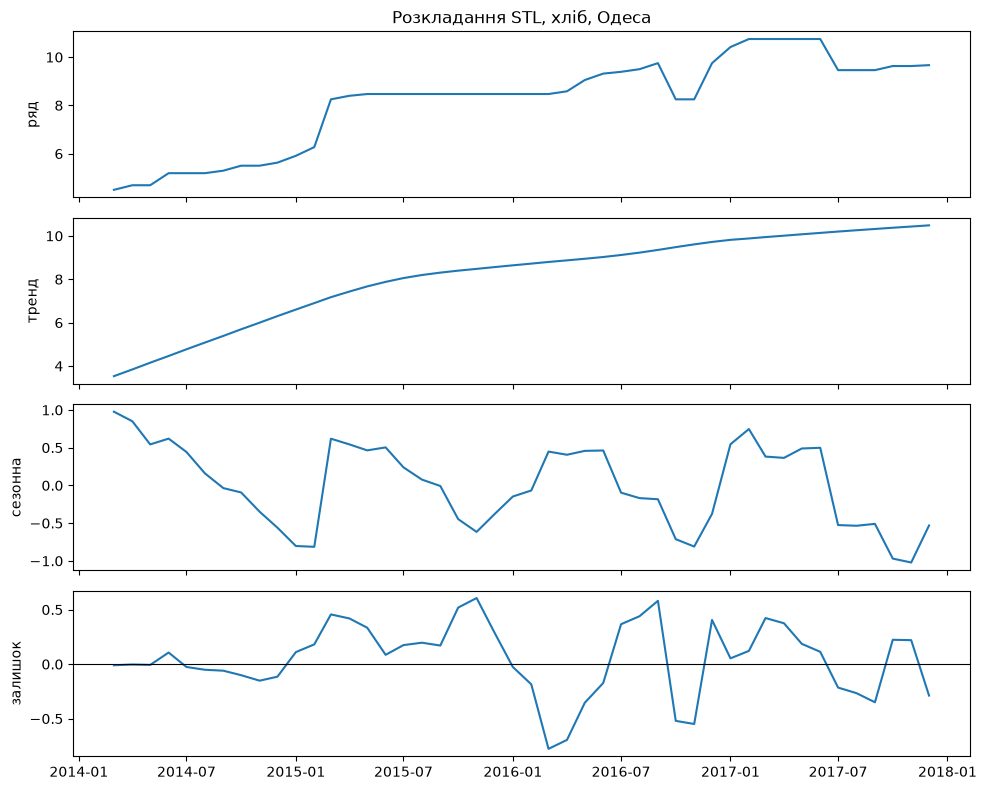

Сила сезонності F_S = 0.74
Сила тренду     F_T = 0.974
місяць    1     2     3     4     5     6     7     8     9     10    11    12
рік                                                                           
2014     NaN   NaN  0.98  0.85  0.54  0.62  0.44  0.16 -0.04 -0.09 -0.35 -0.56
2015   -0.80 -0.81  0.62  0.54  0.46  0.50  0.24  0.08 -0.01 -0.45 -0.62 -0.38
2016   -0.15 -0.07  0.45  0.41  0.46  0.46 -0.10 -0.17 -0.18 -0.71 -0.81 -0.38
2017    0.55  0.75  0.38  0.36  0.49  0.50 -0.53 -0.53 -0.51 -0.97 -1.02 -0.53


In [22]:
from statsmodels.tsa.seasonal import STL

s = s.interpolate()   # на випадок, якщо пропуск ще не заповнено

res = STL(s, period=12).fit()
T, S, R = res.trend, res.seasonal, res.resid

fig, ax = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
ax[0].plot(s);  ax[0].set_ylabel('ряд')
ax[1].plot(T);  ax[1].set_ylabel('тренд')
ax[2].plot(S);  ax[2].set_ylabel('сезонна')
ax[3].plot(R);  ax[3].set_ylabel('залишок')
ax[3].axhline(0, color='black', lw=0.8)
ax[0].set_title('Розкладання STL, хліб, Одеса')
plt.tight_layout()
plt.show()

F_S = max(0, 1 - R.var() / (S + R).var())
F_T = max(0, 1 - R.var() / (T + R).var())
print('Сила сезонності F_S =', round(F_S, 3))
print('Сила тренду     F_T =', round(F_T, 3))

# Перевірка: чи однакова сезонна складова щороку?
table = pd.DataFrame({'рік': S.index.year, 'місяць': S.index.month, 'S': S.round(2)})
print(table.pivot(index='рік', columns='місяць', values='S'))

**Висновок до завдання 4:**

Розкладання STL з періодом 12 наведено на графіку: ряд, тренд, сезонна складова, залишок.

Сила тренду F_T = 0,97, сила сезонності F_S = 0,74.

Формально F_S перевищує поріг 0,3, але сезонності в ряді немає. Сезонна складова не повторюється з року в рік: у січні 2015 вона −0,80 грн, а в січні 2017 +0,55 грн. На графіку видно, що її форма щороку різна. STL сприйняв за «сезон» разові стрибки цін (03.2015, 10–11.2016, 07.2017). Залишок теж не схожий на випадковий шум: найбільші відхилення збігаються з цими стрибками. Ряд визначається трендом і поодинокими різкими змінами ціни, а не сезоном.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

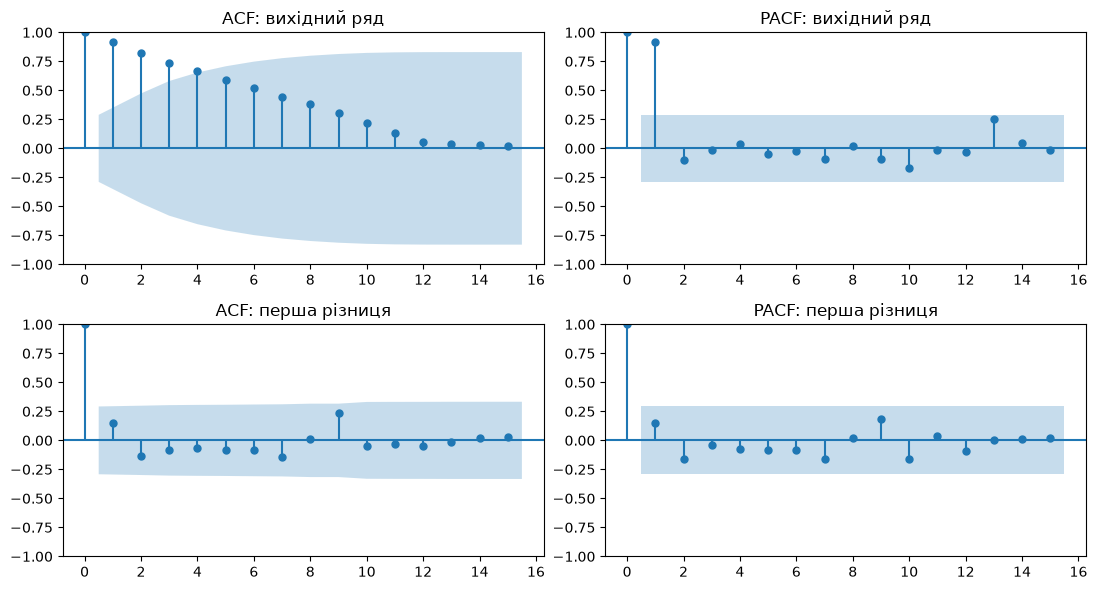

               ADF p  KPSS p
вихідний ряд   0.364    0.01
перша різниця  0.000    0.10


In [24]:
import warnings
warnings.filterwarnings('ignore')
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

s = s.interpolate()
d1 = s.diff().dropna()   # перша різниця

fig, ax = plt.subplots(2, 2, figsize=(11, 6))
plot_acf(s,  lags=15, ax=ax[0, 0], title='ACF: вихідний ряд')
plot_pacf(s, lags=15, ax=ax[0, 1], title='PACF: вихідний ряд')
plot_acf(d1,  lags=15, ax=ax[1, 0], title='ACF: перша різниця')
plot_pacf(d1, lags=15, ax=ax[1, 1], title='PACF: перша різниця')
plt.tight_layout()
plt.show()

table = pd.DataFrame({
    'ADF p':  [adfuller(s)[1], adfuller(d1)[1]],
    'KPSS p': [kpss(s)[1],     kpss(d1)[1]],
}, index=['вихідний ряд', 'перша різниця'])
print(table.round(3))

**Висновок до завдання 5:**

ACF вихідного ряду спадає повільно, що типово для ряду з трендом. Після першої різниці значущих лагів не лишилось.

Вихідний ряд нестаціонарний: ADF p = 0,36, KPSS p ≤ 0,01. Перша різниця стаціонарна: ADF p ≈ 0, KPSS p ≥ 0,10. Тести узгоджуються, тому достатньо одного диференціювання (d = 1).

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [26]:
import numpy as np
s = s.interpolate()

def forecast(train, h, method):
    if method == 'наївний':
        return np.repeat(train.iloc[-1], h)
    if method == 'сезонний наївний':
        return train.iloc[-12:-12 + h].values
    if method == 'середнє':
        return np.repeat(train.mean(), h)
    if method == 'дрейф':
        slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
        return train.iloc[-1] + slope * np.arange(1, h + 1)

methods = ['наївний', 'сезонний наївний', 'середнє', 'дрейф']
rows = []
for m in methods:
    errors, actual = [], []
    for f in range(1, 8):                     # 7 фолдів, відлік від кінця
        train = s[:-3 * f]
        test = s[len(train):len(train) + 3]   # наступні 3 місяці
        errors += list(test.values - forecast(train, 3, m))
        actual += list(test.values)
    e, y = np.array(errors), np.array(actual)
    rows.append([np.mean(np.abs(e)), np.sqrt(np.mean(e**2)), np.mean(np.abs(e / y)) * 100])

result = pd.DataFrame(rows, index=methods, columns=['MAE', 'RMSE', 'MAPE, %'])
print(result.round(3))

# Порівняння: випадковий поділ 75/25 для наївного прогнозу
from sklearn.model_selection import train_test_split
train_idx, test_idx = train_test_split(s.index, test_size=0.25, random_state=42)
known = s.copy()
known[test_idx] = np.nan
naive_pred = known.ffill()[test_idx]       # останнє відоме значення перед точкою
mae_random = np.mean(np.abs(s[test_idx] - naive_pred))
print()
print('MAE наївного, випадковий поділ:', round(mae_random, 3))
print('MAE наївного, рухомий початок: ', round(result.loc['наївний', 'MAE'], 3))
print('Різниця у', round(result.loc['наївний', 'MAE'] / mae_random, 1), 'раза')

                    MAE   RMSE  MAPE, %
наївний           0.586  0.797    6.282
сезонний наївний  1.029  1.274   10.193
середнє           2.137  2.261   21.685
дрейф             0.616  0.873    6.610

MAE наївного, випадковий поділ: 0.342
MAE наївного, рухомий початок:  0.586
Різниця у 1.7 раза


**Висновок до завдання 6:**

Найкращий базис — наївний (MAE = 0,59 грн, MAPE = 6,3 %). Ціна на хліб регулюється і місяцями не змінюється, тому найкраща оцінка майбутньої ціни — поточна. Дрейф трохи гірший, бо продовжує загальне зростання, яке в 2017 році зупинилось. Сезонний наївний і середнє значно гірші, бо сезонності немає, а рівень ціни за чотири роки змінився вдвічі.

За випадкового поділу 75/25 MAE наївного прогнозу дорівнює 0,34 грн, тобто похибка занижена в 1,7 раза. Причина в тому, що модель «бачить» сусідні місяці з майбутнього, а для часових рядів так робити не можна.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

ARIMA(1,1,1):  MAE = 0.589  RMSE = 0.807  MAPE = 6.33 %
Наївний:       MAE = 0.586  RMSE = 0.797  MAPE = 6.282 %


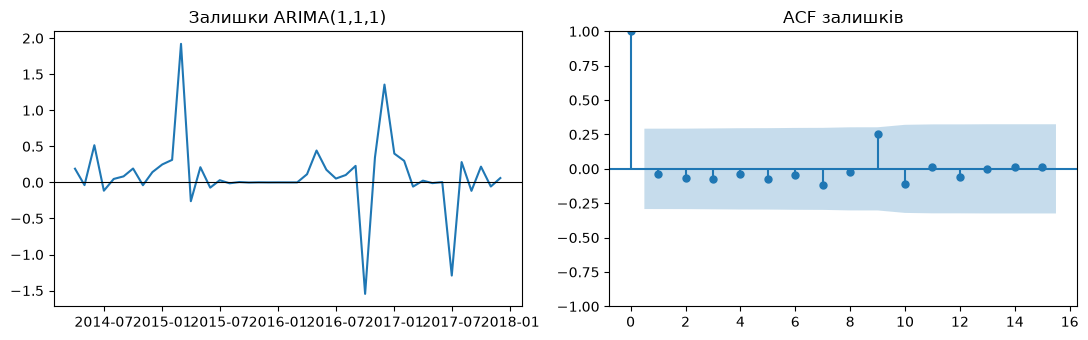

Ljung-Box p (лаг 10): 0.778
Коефіцієнти AR, MA: [-0.197  0.415]


In [27]:
import warnings
warnings.filterwarnings('ignore')
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

# ARIMA(1,1,1) на тих самих 7 фолдах по 3 кроки
ar_true, ar_pred = [], []
for f in range(1, 8):
    train = s[:-3 * f]
    test = s[len(train):len(train) + 3]
    model = ARIMA(train.values, order=(1, 1, 1)).fit()
    ar_pred += list(model.forecast(3))
    ar_true += list(test.values)

y, p = np.array(ar_true), np.array(ar_pred)
e = y - p
print('ARIMA(1,1,1):  MAE =', round(np.mean(np.abs(e)), 3),
      ' RMSE =', round(np.sqrt(np.mean(e**2)), 3),
      ' MAPE =', round(np.mean(np.abs(e / y)) * 100, 3), '%')
print('Наївний:       MAE =', round(result.loc['наївний', 'MAE'], 3),
      ' RMSE =', round(result.loc['наївний', 'RMSE'], 3),
      ' MAPE =', round(result.loc['наївний', 'MAPE, %'], 3), '%')

# Залишки моделі на всьому ряді
full = ARIMA(s.values, order=(1, 1, 1)).fit()
resid = pd.Series(full.resid[1:], index=s.index[1:])   # перший залишок пропускаємо
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(resid)
ax[0].axhline(0, color='black', lw=0.8)
ax[0].set_title('Залишки ARIMA(1,1,1)')
plot_acf(resid, lags=15, ax=ax[1], title='ACF залишків')
plt.tight_layout()
plt.show()

print('Ljung-Box p (лаг 10):', round(acorr_ljungbox(resid, lags=[10])['lb_pvalue'].iloc[0], 3))
print('Коефіцієнти AR, MA:', full.params[:2].round(3))

**Висновок до завдання 7:**

ARIMA(1,1,1) на рухомому початку: MAE = 0,59 грн, RMSE = 0,81 грн, MAPE = 6,3 %.
За ACF і PACF я обрав би ARIMA(0,1,0): тести показали, що потрібне одне диференціювання, а в першій різниці немає жодного значущого лага, тож AR- і MA-частини не потрібні. Така модель збігається з наївним прогнозом.

ARIMA(1,1,1) трохи програє наївному базису (MAE 0,589 проти 0,586). Її коефіцієнти AR = −0,20 і MA = 0,42 майже гасять один одного, тому вона нічого не додає до наївного прогнозу. Для цього ряду модель права на існування не має.

Залишки не мають структури: усі лаги ACF у межах значущості, тест Льюнга–Бокса p = 0,78.
 
Великі залишки трапляються лише в місяці раптових стрибків ціни (03.2015, 10.2016, 12.2016, 07.2017), які модель передбачити не може.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Точка зміни: 03.2015
t        18.641
p         0.000
до        5.296
після     9.210
Name: 2015-03-01 00:00:00, dtype: float64


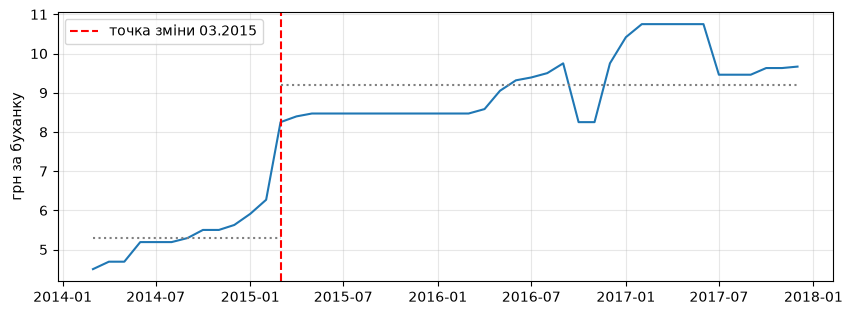

In [28]:
from scipy import stats

rows = []
for i in range(6, len(s) - 6):           # мінімум 6 місяців з кожного боку
    before, after = s[:i], s[i:]
    t, p = stats.ttest_ind(after, before, equal_var=False)
    rows.append([s.index[i], t, p, before.mean(), after.mean()])
scan = pd.DataFrame(rows, columns=['дата', 't', 'p', 'до', 'після']).set_index('дата')

best = scan['t'].abs().idxmax()
print('Точка зміни:', best.strftime('%m.%Y'))
print(scan.loc[best].round(3))

plt.figure(figsize=(10, 3.5))
plt.plot(s)
plt.axvline(best, color='red', ls='--', label='точка зміни ' + best.strftime('%m.%Y'))
plt.hlines(scan.loc[best, 'до'], s.index[0], best, color='gray', ls=':')
plt.hlines(scan.loc[best, 'після'], best, s.index[-1], color='gray', ls=':')
plt.ylabel('грн за буханку')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Висновок до завдання 8:**

Точка зміни рівня — березень 2015: t = 18,6, середня ціна до 5,30 грн, після 9,21 грн. Точка значуща: ціна за місяць зросла на 1,98 грн і назад не повернулась. Імовірна причина — девальвація гривні на початку 2015 року.

Це не сезонний сплеск: у березні інших років стрибка немає, а новий рівень зберігся. Провал у 10–11.2016 тимчасовий і зміною режиму не є.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [31]:
from statsmodels.tsa.stattools import adfuller

v = df[df['ринок'] == 'Vinnytsia']
buck = v[v['товар'] == 'Buckwheat grits - Retail'].set_index('date')['ціна'].sort_index()
beef = v[v['товар'] == 'Meat (beef) - Retail'].set_index('date')['ціна'].sort_index()

# [1] Сітку створено, але не застосовано
print('[1] Спостережень у звіті:', len(buck), '| місяців у періоді:', len(grid))

# [2] Пропуск є, але звіт його не бачить
print('[2] Пропусків у звіті:', buck.isna().sum(), '| насправді:', buck.reindex(grid).isna().sum())

# [3] Порівняння лише крайніх точок приховує пік
print('[3] Початок:', buck.iloc[0], '| кінець:', buck.iloc[-1], '| максимум:', buck.max())

# [4] MAE у гривнях для різних товарів — у відсотках висновок протилежний
for name, x in [('гречка', buck), ('яловичина', beef)]:
    e = (x - x.shift(1)).dropna()
    print('[4]', name, 'MAPE =', round((e.abs() / x[e.index]).mean() * 100, 1), '%')

# [6] Сезонність без F_S
r = STL(buck.reindex(grid).interpolate(), period=12, robust=True).fit()
print('[6] F_S =', round(max(0, 1 - r.resid.var() / (r.seasonal + r.resid).var()), 2))

# [7] ADF прочитано навпаки
print('[7] ADF p =', round(adfuller(buck)[1], 3), '> 0.05 → ряд НЕстаціонарний')

# [8] Поріг аномалій не той
z = (buck - buck.mean()) / buck.std()
print('[8] Аномалій при 1.3σ:', (z.abs() > 1.3).sum(), '| при 2σ:', (z.abs() > 2).sum())

# [9] MAE 8.73 — це не «висока точність»
print('[9] MAE 8.73 грн =', round(8.73 / buck.mean() * 100), '% від середньої ціни')

# [10] Прогноз падає, а висновок — про зростання
fc = ARIMA(buck.values, order=(2, 2, 1)).fit().forecast(12)
print('[10] Остання ціна:', buck.iloc[-1], '| прогноз:', round(fc[-1], 2))

# [11] Вісь Y не з нуля
print('[11] Вісь Y починається з', round(buck['2016-01':'2016-06'].min() * 0.995, 1), 'грн')

[1] Спостережень у звіті: 45 | місяців у періоді: 46
[2] Пропусків у звіті: 0 | насправді: 1
[3] Початок: 7.1633 | кінець: 17.6733 | максимум: 36.93
[4] гречка MAPE = 6.2 %
[4] яловичина MAPE = 1.9 %
[6] F_S = 0.26
[7] ADF p = 0.233 > 0.05 → ряд НЕстаціонарний
[8] Аномалій при 1.3σ: 12 | при 2σ: 0
[9] MAE 8.73 грн = 41 % від середньої ціни
[10] Остання ціна: 17.6733 | прогноз: 8.95
[11] Вісь Y починається з 24.8 грн


**Висновок до завдання 9:**

| Клітинка | Помилка | Чим небезпечна |
|---|---|---|
| [1] | Сітку `grid` створено, але не застосовано | Завантажено 45 місяців замість 46 |
| [2] | Пропуск 08.2017 не знайдено | Хибний висновок «дані повні» |
| [3] | Подорожчання за двома крайніми точками | Прихований пік 36,9 грн |
| [4] | MAE у гривнях для товарів різної ціни | Висновок перевернутий: яловичина 1,9 %, гречка 6,2 % |
| [5] | Кореляцію видано за причину | Хибний причинний висновок |
| [6] | Сезонність без F_S | F_S = 0,26 < 0,3, сезонності немає |
| [7] | ADF прочитано навпаки, подвійне диференціювання | Неправильна модель |
| [8] | Поріг 1,3σ замість 2σ, ряд із трендом | При 2σ аномалій 0 |
| [9] | Випадковий поділ, немає базису | MAE = 41 % від ціни, а не «висока точність» |
| [10] | Прогноз іншою моделлю | Прогноз падає, а висновок говорить про зростання |
| [11] | Вісь Y не з нуля | Перебільшує зміни |

**Як виправити три найсерйозніші:**

1. **[9]** — оцінювати модель рухомим початком і порівнювати з наївним прогнозом.
2. **[10]** — будувати прогноз тією самою моделлю, яку перевіряли, і показувати довірчі інтервали.
3. **[1]–[2]** — накласти ряд на повну місячну сітку й заповнити пропуск.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [32]:
s = s.interpolate()   # на випадок, якщо пропуск ще не заповнено

out = pd.DataFrame({'date': s.index.strftime('%Y-%m-%d'), 'price': s.values})
out.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

# Перевірка: читаємо файл назад
check = pd.read_csv('ряд_для_orange.csv')
print('Рядків даних:', len(check))
print('Порожніх значень:', check.isna().sum().sum())
print(check.head(3))
print(check[check['date'] == '2017-08-01'])

Рядків даних: 46
Порожніх значень: 0
         date  price
0  2014-03-01   4.50
1  2014-04-01   4.69
2  2014-05-01   4.69
          date  price
41  2017-08-01   9.46


**Висновок до завдання 10:**

Файл ряд_для_orange.csv містить 46 рядків даних і не має порожніх значень. Дата записана у форматі РРРР-ММ-ДД, пропуск за 08.2017 заповнено значенням 9,46 грн.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

**Висновок до завдання 11:**
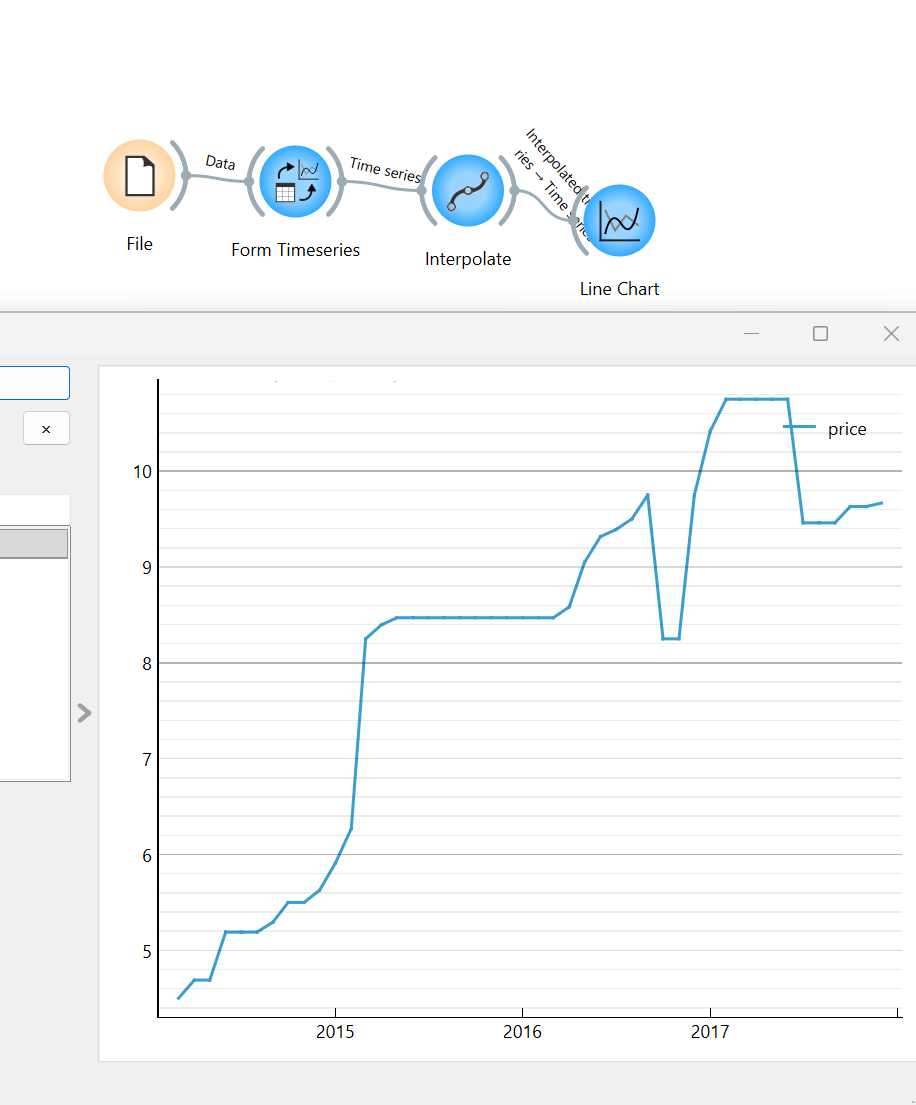
Потік File → Form Timeseries → Interpolate → Line Chart побудовано. У Orange 3.40 віджет As Timeseries називається Form Timeseries. Стовпець date розпізнано як datetime, price як numeric, завантажено 46 точок. Графік у Orange збігається з графіком із завдання 3, тож обидва середовища працюють з однаковими даними.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

In [ ]:
# Завдання 12. Автокореляція та диференціювання


**Висновок до завдання 12:**

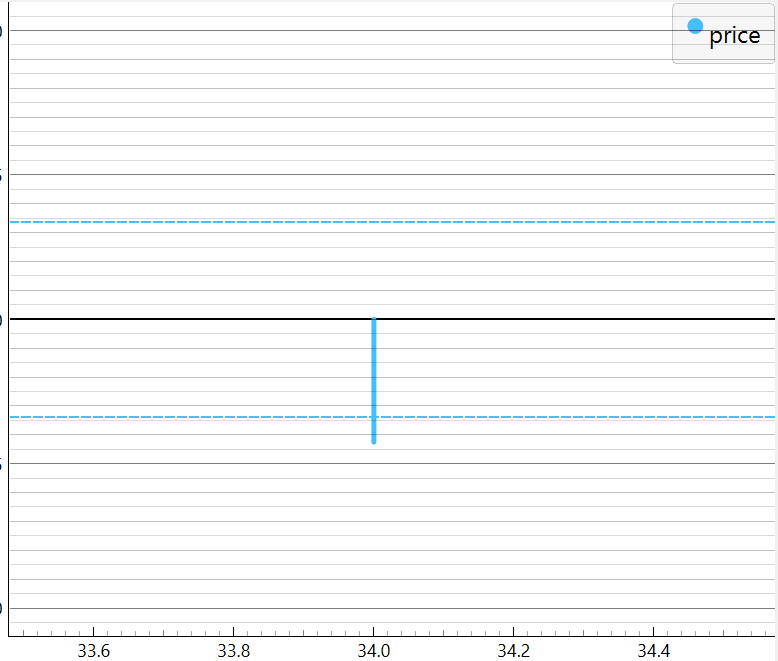

*Рис. 1. Корелограма вихідного ряду в Orange: показано лише один локальний пік (лаг 34).*

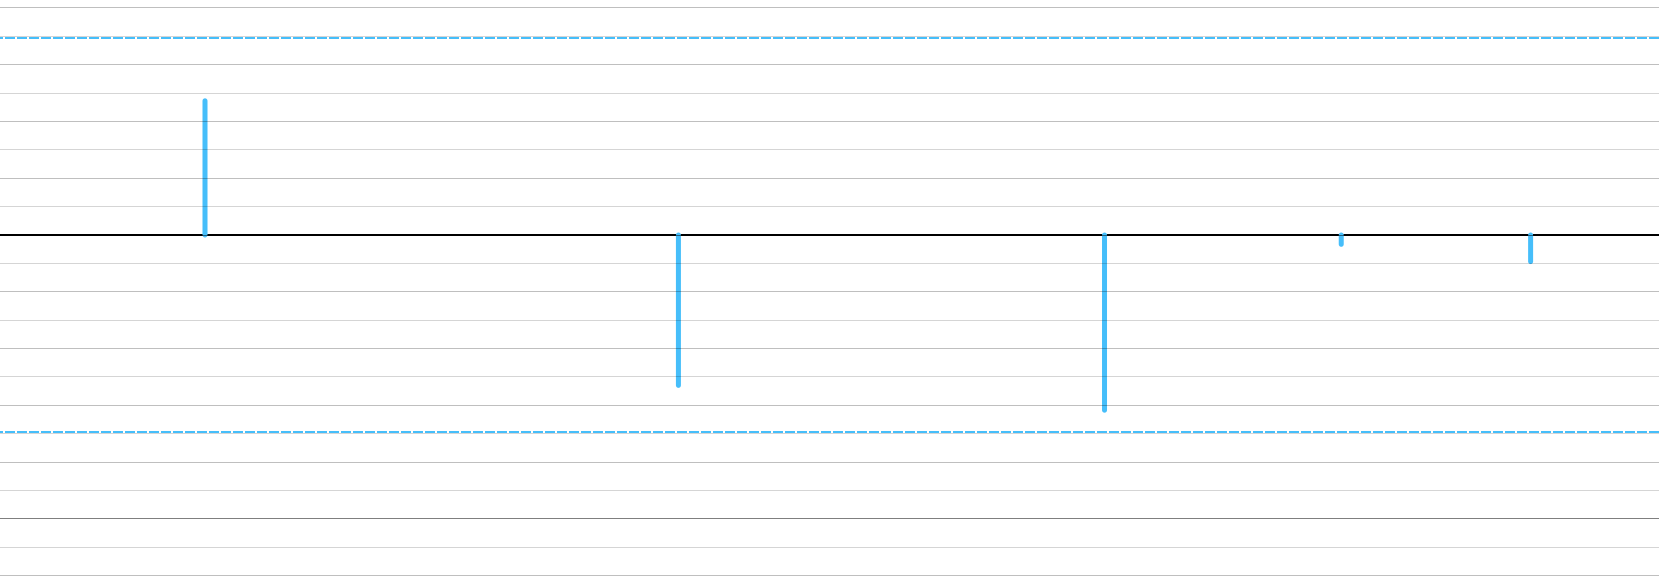

*Рис. 2. Корелограма першої різниці: піки на лагах 9, 19, 28, 33, 37, усі в межах значущості.*

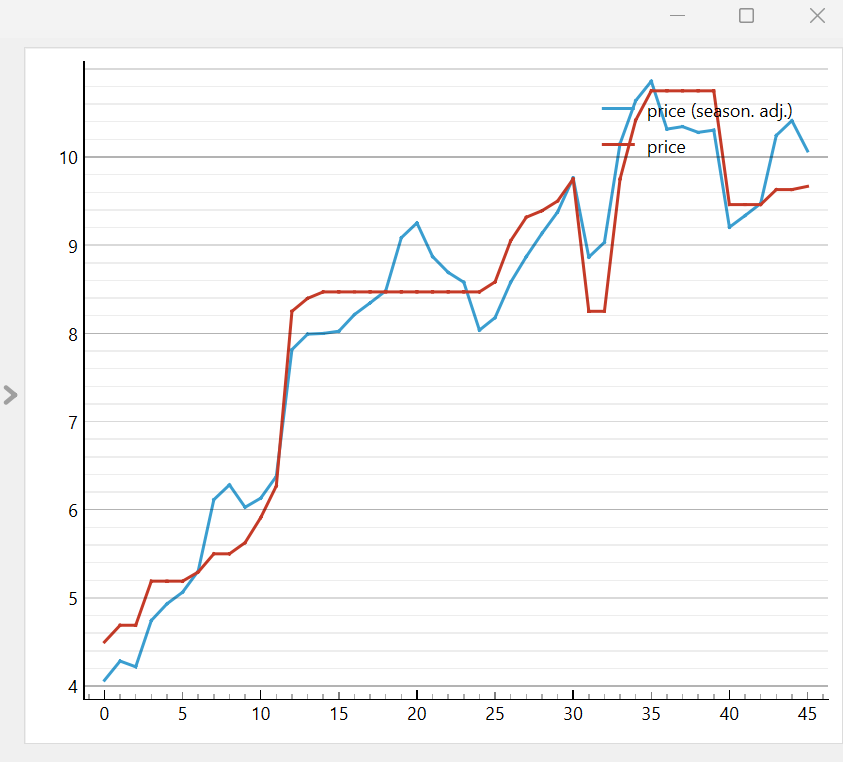

*Рис. 3. Сезонно скоригований ряд (Seasonal Adjustment, період 12).*

1. Корелограма Orange показує не всі лаги, а лише локальні піки ACF. Висновок збігається із завданням 5: вихідний ряд має сильну автокореляцію, а після диференціювання значущих лагів немає.
2. Через помилку в Timeseries 0.6.3 (*variable date is not in domain*) Seasonal Adjustment довелося запускати без стовпця дати, через Select Columns. Після вилучення «сезону» ряд став більш хвилястим, ніж вихідний: віджет відняв сезонну складову, якої насправді немає. Це підтверджує висновок STL із завдання 4: сезонності в ряді немає.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [16]:
# Завдання 13. Модель і оцінювання

**Висновок до завдання 13:**
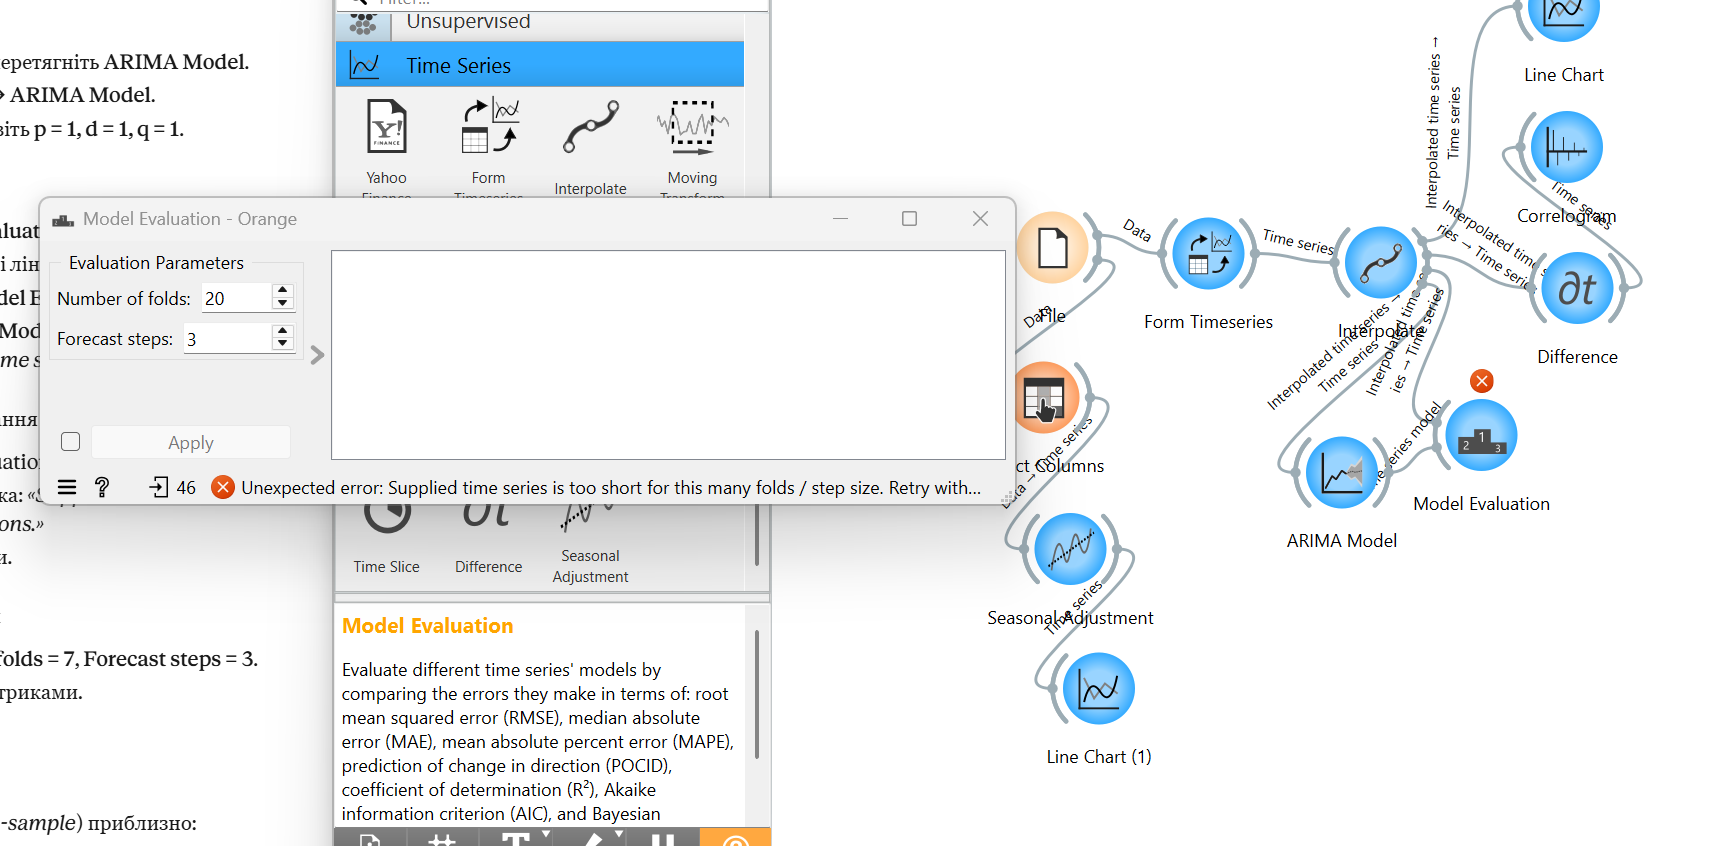
*Рис. 1. Помилка Model Evaluation за типових налаштувань (20 фолдів × 3 кроки).*

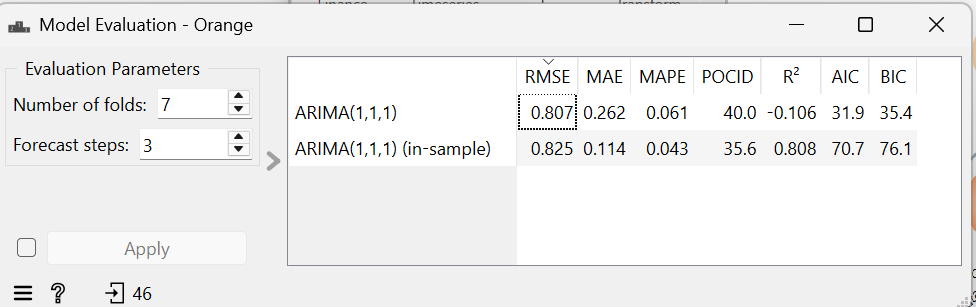
*Рис. 2. Результати Model Evaluation для ARIMA(1,1,1), 7 фолдів × 3 кроки.*

1. ARIMA(1,1,1) на 7 фолдах по 3 кроки: RMSE = 0,807, MAE = 0,262, MAPE = 0,061, POCID = 40,0.
2. За типових налаштувань Orange видає помилку *«Supplied time series is too short for this many folds / step size»*. Віджет перевіряє умову: фолди × кроки + порядок моделі ≤ довжина ряду. При 20 фолдах 20 × 3 + 1 = 61 > 46, тобто ряд закороткий. При 7 фолдах 7 × 3 + 1 = 22 ≤ 46.
3. Orange відлічує фолди від кінця ряду. Модель навчається на даних до 09.2017, 06.2017, 03.2017, 12.2016, 09.2016, 06.2016 і 03.2016 і щоразу прогнозує наступні 3 місяці. Разом перевіряється останній 21 місяць (04.2016–12.2017), так само як у Python.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [33]:
y, p = np.array(ar_true), np.array(ar_pred)
e = y - p

table = pd.DataFrame({
    'Orange':  [0.807, 0.262, 0.061, 40.0],
    'Python (формула Orange)': [np.sqrt(np.mean(e**2)),                      # RMSE
                                np.median(np.abs(e)),                        # MAE = медіана
                                np.mean(np.abs(e)) / np.mean(np.abs(y)),     # MAPE = частка
                                100 * np.mean(np.diff(y) * np.diff(p) > 0)], # POCID
    'Python (звичайна формула)': [np.sqrt(np.mean(e**2)),
                                  np.mean(np.abs(e)),
                                  np.mean(np.abs(e / y)) * 100,
                                  np.nan],
}, index=['RMSE', 'MAE', 'MAPE', 'POCID'])
print(table.round(3))

       Orange  Python (формула Orange)  Python (звичайна формула)
RMSE    0.807                    0.807                      0.807
MAE     0.262                    0.262                      0.589
MAPE    0.061                    0.061                      6.330
POCID  40.000                   40.000                        NaN


**Висновок до завдання 14:**

| Метрика | Orange | Python | Формула Orange |
|---|---|---|---|
| RMSE | 0,807 | 0,807 | √(середнє e²) |
| MAE | 0,262 | 0,262 | медіана \|e\| |
| MAPE | 0,061 | 0,061 | середнє \|e\| / середнє \|y\| |
| POCID | 40,0 | 40,0 | 100 · частка збігів напрямку зміни |

1. Своїй назві не відповідає **MAE**: в Orange це медіанна, а не середня абсолютна похибка. У нашому ряді більшість похибок малі, а кілька великих (стрибки ціни), тому медіана 0,26 більш ніж удвічі менша за середнє 0,59. MAPE теж рахується інакше: середня похибка ділиться на середню ціну, і результат є часткою (0,061), а не відсотком (6,33 %).
2. Одразу збігся **RMSE**, бо в обох середовищах він рахується за однаковою формулою.
3. Перш ніж порівнювати числа з різних інструментів, треба перевірити, за якими формулами вони пораховані. Однакова назва метрики не гарантує однакової формули.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [34]:
# Завдання 15. Матриця напрямку зміни
y, p = np.array(ar_true), np.array(ar_pred)

def direction(x):
    return np.where(x > 0, 'зросла', np.where(x < 0, 'впала', 'без змін'))

fact = direction(np.diff(y))    # що сталося насправді
model = direction(np.diff(p))   # що передбачила модель

m = pd.crosstab(pd.Series(fact, name='Насправді'), pd.Series(model, name='Модель'))
print(m)

correct = ((fact == 'зросла') & (model == 'зросла')).sum() + ((fact == 'впала') & (model == 'впала')).sum()
print('Правильних:', correct, 'з', len(fact), '→ POCID =', 100 * correct / len(fact))

Модель     впала  зросла
Насправді               
без змін       2       5
впала          3       2
зросла         3       5
Правильних: 8 з 20 → POCID = 40.0


**Висновок до завдання 15:**

| Насправді \ Модель | впала | зросла |
|---|---|---|
| зросла | 3 | **5** |
| впала | **3** | 2 |
| без змін | 2 | 5 |

1. Модель правильно вгадала напрямок у 5 + 3 = 8 випадках із 20, тобто 40 %. Це точно збігається з POCID в Orange.
2. Для рішення «купувати зараз чи чекати» модель некорисна: 40 % гірше, ніж підкидання монетки (50 %). До того ж у 7 випадках із 20 ціна взагалі не змінювалась, а модель завжди передбачає хоч невелику зміну.
3. MAE і RMSE відповідають на питання «наскільки модель помиляється в гривнях», а POCID — «чи вгадує вона напрямок». Модель може мати малу похибку, але при цьому погано вгадувати напрямок, як у нашому випадку.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?



 Сезонності в ряді немає. STL дав F_S = 0,74, але сезонна складова щороку різна, а графік по роках не показує спільного малюнка. Сезонне коригування в Orange лише додало в ряд штучні хвилі.

 Найкращим методом виявився наївний прогноз (MAE = 0,59 грн). ARIMA(1,1,1) його не перевершила: її коефіцієнти майже гасять один одного, і модель фактично зводиться до того самого наївного прогнозу.

 Точку зміни режиму знайдено в березні 2015: ціна зросла з 5,30 до 9,21 грн у середньому і назад не повернулась. Імовірне пояснення — девальвація гривні на початку 2015 року.
 RMSE в обох середовищах збігся, а MAE і MAPE ні, бо Orange рахує їх за іншими формулами: MAE як медіану похибок, MAPE як частку середньої похибки від середньої ціни. Усі чотири метрики Orange вдалося відтворити в Python до третього знака.
 
Через те що ряд має лише 46 спостережень, неможливо надійно перевірити сезонність: повних років менше чотирьох, тож разові стрибки легко сприйняти за сезон. Також неможливо оцінити модель на більшій кількості фолдів і зрозуміти, як часто трапляються зміни режиму.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude (Anthropic), модель Claude Opus 5.5, чат claude.ai |
| Для яких саме завдань | Для всіх завдань: підготовка файлів, код для завдань 1–10, 14–15, покрокові інструкції для Orange (11–13), чернетки висновків |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Код, чернетки висновків, пояснення графіків і метрик, допомога з налаштуванням Orange |
| Що ви змінили у згенерованому результаті й чому | Просив спростити код і скоротити висновки; змінив третій графік у завданні 3, бо початковий варіант дублював перший |
| Що з отриманого ви перевірили самостійно і яким способом | Запускав увесь код у зошиті й звіряв виводи; порівняв графіки Python і Orange; перевірив, що метрики Orange збігаються з відтвореними в Python |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Так: графік STL через res.plot() не відображався; ШІ порадив обхід помилки Seasonal Adjustment через «Sequence implied by instance order», який не спрацював; назва віджета As Timeseries у методичці застаріла (у новій версії — Form Timeseries) |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: _____25.10.2026________